# Toy model (3 reactions) as a COBRAk model, with forced under- and overexpression

Builds the toy model of the supplement (TS, AAS, R) as a COBRAk `Model`, and scans the growth rate while the proteome fraction of each enzyme is forced to values between 0 and 1. The scan is done with the enzyme-constrained LP (kcat and MW only) and with the kinetic NLP (Km, no dG0).

| Input | Source in the manuscript |
|---|---|
| Stoichiometry | Supplement, toy model: mass fraction matrix (TS: Cext -> S, AAS: S -> AA, R: AA -> P) |
| kcat | Supplement, toy model (forward values 10, 8, 4.55) |
| Km | Supplement, toy model (K matrix) |
| Density, biomass composition, external carbon source | GBA result file of the toy model (`B_rev_protein_cost.csv`), at the growth optimum |

**Units.** Every toy species gets the same molar mass `M_TOY`, so the mass fraction matrix is also the molar stoichiometry (all coefficients 1). With `M_TOY` = 1000 g/mol, 1 mmol of a species is 1 g, and the default concentration bounds of COBRAk (1e-6 to 0.02 mol/L) are 0.001 to 20 g/L. The toy parameters are in g/L and g/(g h) and are converted to the COBRAk units in the model cell.

**Comparison with GBA.** The GBA results are read from `B_rev_protein_cost.csv` and plotted on top of the COBRAk results. The same file gives the conditions of the GBA simulation (density, composition of the biomass and external concentration of the carbon source) at the growth optimum, and the COBRAk model uses them.

**Free choice.** The enzyme molecular weights are not used in GBA since everything is in mass fraction. They cancel in the conversion of the kcat values, so they do not change the results.

## 1. Imports and configuration

In [1]:
import os
import sys
import csv
import time
import numpy as np
from math import log
import json
import logging
from copy import deepcopy
import matplotlib.pyplot as plt

from cobrak.constants import ALL_OK_KEY
from cobrak.dataclasses import (
    Enzyme,
    EnzymeReactionData,
    HillCoefficients,
    Metabolite,
    Model,
    Reaction,
    Solver,
)
from cobrak.io import json_write
from cobrak.lps import perform_lp_optimization
from cobrak.nlps import perform_nlp_irreversible_optimization
from cobrak.standard_solvers import CPLEX, IPOPT

for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "LOKY_MAX_CPU_COUNT"):
    os.environ[name] = "32"
os.environ["PATH"] = "/home/users/dszeliova/.conda/envs/optenz/bin:" + os.environ["PATH"]

IPOPT = Solver(name="ipopt")

In [15]:
M_TOY = 1000.0        # g/mol, molar mass of every toy species (1 mmol = 1 g)

# Molecular weight of each enzyme in kDa (1 kDa = 1000 g/mol)
ENZ_MW_KDA = {"TS": 100.0, "AAS": 400.0, "R": 826.0}

# GBA results of the toy model (one row per forced proteome fraction)
GBA_CSV = "../data/B_protein_cost.csv"

REVERSIBLE_KINETICS = "_rev" in GBA_CSV  # True: products inhibit TS and AAS (K+ of the K matrix). False: irreversible
K_INF = 1e6                  # mol/L, Km of products without product inhibition (K+ -> infinity)

## 2. Supplement data

In [16]:
# Mass fraction matrix of the toy model = molar stoichiometry (all species have the same molar mass)
stoich = {
    "TS":  {"Cext": -1.0, "S": 1.0},
    "AAS": {"S": -1.0, "AA": 1.0},
    "R":   {"AA": -1.0, "P": 1.0},
}

# Forward turnover numbers, g product / (g protein h).
KCAT_MASS = {"TS": 10.0, "AAS": 8.0, "R": 4.55}

# Km matrix (g/L). Substrates: K-. Products: K+.
K_GL = {
    "TS":  {"Cext": 10.0, "S": 30.0},
    "AAS": {"S": 10.0, "AA": 24.0},
    "R":   {"AA": 8.0},
}
IRREVERSIBLE = ["R"]            # the ribosome reaction is always irreversible
if not REVERSIBLE_KINETICS:
    IRREVERSIBLE = ["TS", "AAS", "R"]

# GBA results
with open(GBA_CSV) as f:
    gba_rows = list(csv.DictReader(f))
gba_reaction = np.array([row["reaction"] for row in gba_rows])
gba = {key: np.array([float(row[key]) for row in gba_rows]) for key in gba_rows[0] if key != "reaction"}

# Conditions of the GBA simulation at the growth optimum (the row with the highest growth rate)
i_opt = int(np.argmax(gba["mu"]))
gba_optimum_conc = {m: gba[f"c.{m}"][i_opt] for m in ("S", "AA", "P")}   # g/L
RHO_TOY = sum(gba_optimum_conc.values())                                   # g/L, cell density
A_CEXT_GL = gba["c.x_S"][i_opt]                                            # g/L, external carbon source
biomass_fraction = {m: c / RHO_TOY for m, c in gba_optimum_conc.items()}   # g/gDW

print(f"GBA optimum: growth rate {gba['mu'][i_opt]:.4f} 1/h, density {RHO_TOY:.1f} g/L, external carbon source {A_CEXT_GL:.0f} g/L")
print("biomass fractions:", {m: round(float(f), 4) for m, f in biomass_fraction.items()})

GBA optimum: growth rate 1.7039 1/h, density 340.0 g/L, external carbon source 100 g/L
biomass fractions: {'S': 0.1372, 'AA': 0.1103, 'P': 0.7525}


## 3. Model

* `kcat_molar [1/h] = kcat_mass * MW_enzyme * 1000 / m_l`, with `m_l` the mass of one mole of the reaction (`M_TOY` here).
* `Km [mol/L] = Km [g/L] / M_TOY`.
* The biomass reaction consumes the biomass composition in mmol/gDW, so its flux is the growth rate. The metabolite pools S and AA are part of it because growth dilutes them.
* The enzyme pool is the protein fraction of the biomass.

In [17]:
reaction_mass = M_TOY   # g/mol, one mole of every toy reaction (all coefficients are 1)

enzymes = {f"E_{r}": Enzyme(molecular_weight=ENZ_MW_KDA[r], name=f"{r} protein") for r in stoich}

reactions = {}
for r, st in stoich.items():
    kcat_molar = KCAT_MASS[r] * ENZ_MW_KDA[r] * 1000.0 / reaction_mass
    k_ms = {m: K_GL[r][m] / M_TOY for m in K_GL[r]}
    if r in IRREVERSIBLE:
        for m, coefficient in st.items():
            if coefficient > 0:
                k_ms[m] = K_INF
    reactions[r] = Reaction(
        stoichiometries=st,
        min_flux=0.0,
        max_flux=1000.0,
        enzyme_reaction_data=EnzymeReactionData(identifiers=[f"E_{r}"], k_cat=kcat_molar, k_ms=k_ms),
        name=r,
    )

reactions["EX_Cext"] = Reaction(stoichiometries={"Cext": +1.0}, max_flux=1000.0, name="Carbon source supply")
reactions["Biomass"] = Reaction(
    stoichiometries={m: -1000.0 * f / M_TOY for m, f in biomass_fraction.items()},
    max_flux=10.0,
    name="Biomass",
)

# Concentration bounds (mol/L):
# - minimum: default of COBRAk (1e-6 mol/L)
# - maximum: the concentration of the species in the biomass (density * fraction), but not below
#   the default maximum of COBRAk (0.02 mol/L), so the biomass can be reached
default_log_max_conc = Metabolite(name="default").log_max_conc
metabolites = {}
for m in ["S", "AA", "P"]:
    c_biomass = RHO_TOY * biomass_fraction[m] / M_TOY   # mol/L
    metabolites[m] = Metabolite(name=m, log_max_conc=max(default_log_max_conc, log(c_biomass)))
c_cext = A_CEXT_GL / M_TOY   # mol/L
metabolites["Cext"] = Metabolite(name="Cext", log_min_conc=log(c_cext), log_max_conc=log(c_cext))

model = Model(
    metabolites=metabolites,
    reactions=reactions,
    enzymes=enzymes,
    max_prot_pool=biomass_fraction["P"],
)

for r, reaction in model.reactions.items():
    left = [f"{abs(v):.3g} {m}" for m, v in reaction.stoichiometries.items() if v < 0]
    right = [f"{v:.3g} {m}" for m, v in reaction.stoichiometries.items() if v > 0]
    print(f"{r:8s} {' + '.join(left)} -> {' + '.join(right)}")
for r in stoich:
    print(f"{r:4s} kcat = {model.reactions[r].enzyme_reaction_data.k_cat:10.1f} 1/h")

# Mass balance: 0 for the internal reactions, 1000 mg per gDW for the biomass reaction
for r in stoich:
    assert abs(sum(stoich[r].values())) < 1e-12, r
assert abs(sum(v * M_TOY for v in model.reactions["Biomass"].stoichiometries.values()) + 1000.0) < 1e-6

TS       1 Cext -> 1 S
AAS      1 S -> 1 AA
R        1 AA -> 1 P
EX_Cext   -> 1 Cext
Biomass  0.137 S + 0.11 AA + 0.753 P -> 
TS   kcat =     1000.0 1/h
AAS  kcat =     3200.0 1/h
R    kcat =     3758.3 1/h


## 4. Optimum: enzyme-constrained LP and kinetic NLP

In [18]:
ec_result = perform_lp_optimization(
    model,
    objective_target="Biomass",
    objective_sense=+1,
    with_enzyme_constraints=True,
    solver=CPLEX,
)
print("LP growth rate:", round(ec_result["Biomass"], 4), "1/h")

variability_dict = {r: (0.0, reaction.max_flux) for r, reaction in model.reactions.items()}
nlp_result = perform_nlp_irreversible_optimization(
    model,
    objective_target="Biomass",
    objective_sense=+1,
    variability_dict=variability_dict,
    with_kappa=True,
    with_gamma=False,
    with_iota=False,
    with_alpha=False,
    solver=IPOPT,
)
print("NLP growth rate:", round(nlp_result["Biomass"], 4), "1/h")

print(f"{'enzyme':6s} {'LP phi':>8s} {'NLP phi':>8s} {'kappa':>7s}")
for r in stoich:
    phi_lp = ec_result[f"enzyme_E_{r}_of_{r}"] * ENZ_MW_KDA[r] / model.max_prot_pool
    phi_nlp = nlp_result[f"enzyme_E_{r}_of_{r}"] * ENZ_MW_KDA[r] / model.max_prot_pool
    print(f"{r:6s} {phi_lp:8.3f} {phi_nlp:8.3f} {nlp_result.get('kappa_var_' + r, float('nan')):7.3f}")

LP growth rate: 2.0162 1/h
NLP growth rate: 1.7041 1/h
enzyme   LP phi  NLP phi   kappa
TS        0.268    0.249   0.909
AAS       0.289    0.297   0.824
R         0.443    0.454   0.824


## 5. Forced under- and overexpression

For each enzyme, its share `phi` of the enzyme pool is fixed. All other enzymes and fluxes are free, and the growth rate is maximized. At `phi = 0` and `phi = 1` the growth rate is 0 (the reaction is essential, or no other enzyme is left), so these two points are set without solving. Points where IPOPT does not converge are stored as `None` and left out of the plot.

In [6]:
logging.getLogger("pyomo.core").setLevel(logging.ERROR)

PHI_GRID = np.linspace(0.0, 1.0, 101)
PRINT_EVERY = 10   # print the progress after every PRINT_EVERY grid points
suffix = ["", "_rev"][REVERSIBLE_KINETICS]
SCAN_JSON = f"../data/toy_expression_scan_results{suffix}.json"
FIGURE_FILE = f"../figures/toy_expression_scan{suffix}.png"


def model_with_forced_enzyme(base_model, reac_id, phi):
    forced_model = deepcopy(base_model)
    enzyme = forced_model.enzymes[f"E_{reac_id}"]
    concentration = phi * forced_model.max_prot_pool / enzyme.molecular_weight   # mmol/gDW
    enzyme.min_conc = concentration
    enzyme.max_conc = concentration+1e-6
    return forced_model


scan = {r: {"phi": [], "linear": [], "nonlinear": []} for r in stoich}
failed_points = []
n_points = len(PHI_GRID)
start_time = time.perf_counter()

for enzyme_index, r in enumerate(stoich, start=1):
    print(f"[{enzyme_index}/{len(stoich)}] enzyme {r}: {n_points} grid points", flush=True)
    for point_index, phi in enumerate(PHI_GRID, start=1):
        phi = float(phi)
        if phi <= 0.0 or phi >= 1.0:
            mu_linear, mu_nonlinear = 0.0, 0.0
        else:
            forced_model = model_with_forced_enzyme(model, r, phi)
            mu_linear = perform_lp_optimization(
                forced_model,
                objective_target="Biomass",
                objective_sense=+1,
                with_enzyme_constraints=True,
                solver=CPLEX,
            )["Biomass"]
            mu_nonlinear = None

            try:
                scan_result = perform_nlp_irreversible_optimization(
                    forced_model,
                    objective_target="Biomass",
                    objective_sense=+1,
                    variability_dict=variability_dict,
                    with_kappa=True,
                    with_gamma=False,
                    with_iota=False,
                    with_alpha=False,
                    solver=IPOPT,
                )
            except Exception:   # IPOPT can stop with an error status far from the optimum
                pass
            if scan_result[ALL_OK_KEY]:
                mu_nonlinear = scan_result["Biomass"]

            if mu_nonlinear is None:
                failed_points.append((r, round(phi, 5)))
        scan[r]["phi"].append(phi)
        scan[r]["linear"].append(mu_linear)
        scan[r]["nonlinear"].append(mu_nonlinear)
        if point_index % PRINT_EVERY == 0 or point_index == n_points:
            print(f"    {r}: point {point_index}/{n_points}, phi = {phi:.2f}, "
                  f"elapsed {time.perf_counter() - start_time:.1f} s, "
                  f"NLP points without solution so far: {len(failed_points)}", flush=True)

with open(SCAN_JSON, "w") as f:
    json.dump(scan, f)
print("NLP points without a converged solution:", len(failed_points), failed_points)

[1/3] enzyme TS: 101 grid points
    TS: point 10/101, phi = 0.09, elapsed 67.0 s, NLP points without solution so far: 0
    TS: point 20/101, phi = 0.19, elapsed 153.6 s, NLP points without solution so far: 0
    TS: point 30/101, phi = 0.29, elapsed 235.9 s, NLP points without solution so far: 0
    TS: point 40/101, phi = 0.39, elapsed 318.7 s, NLP points without solution so far: 0
    TS: point 50/101, phi = 0.49, elapsed 390.7 s, NLP points without solution so far: 0
    TS: point 60/101, phi = 0.59, elapsed 473.8 s, NLP points without solution so far: 0
    TS: point 70/101, phi = 0.69, elapsed 552.3 s, NLP points without solution so far: 0
    TS: point 80/101, phi = 0.79, elapsed 641.6 s, NLP points without solution so far: 0
    TS: point 90/101, phi = 0.89, elapsed 716.3 s, NLP points without solution so far: 0
    TS: point 100/101, phi = 0.99, elapsed 815.3 s, NLP points without solution so far: 0
    TS: point 101/101, phi = 1.00, elapsed 815.3 s, NLP points without soluti

### Plot

In [21]:
with open('../data/toy_expression_scan_results__rev.json', "r") as f:
    scan = json.load(f)

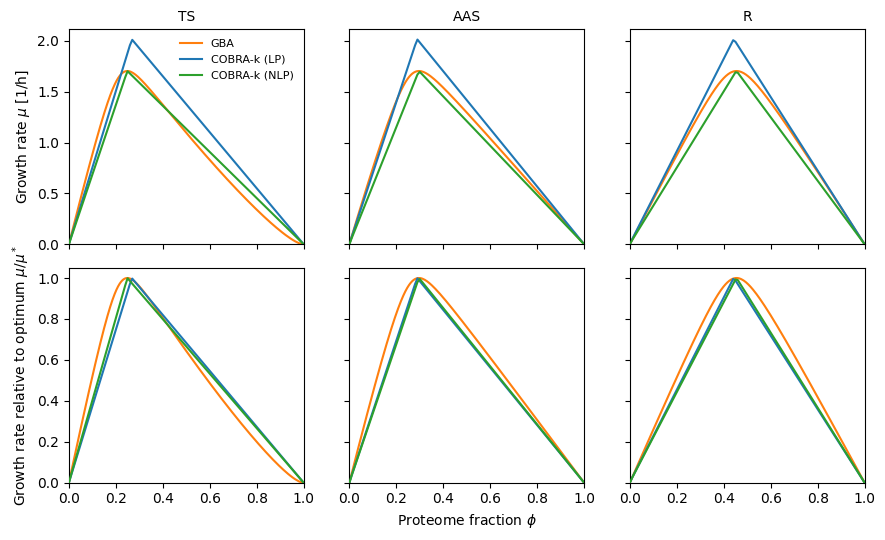

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(9, 5.5), sharex=True, sharey="row")
for col, r in enumerate(stoich):
    phi = np.array(scan[r]["phi"])
    linear = np.array(scan[r]["linear"], dtype=float)
    nonlinear = np.array([np.nan if v is None else v for v in scan[r]["nonlinear"]], dtype=float)
    in_r = gba_reaction == r
    order = np.argsort(gba["phi"][in_r])
    gba_phi = gba["phi"][in_r][order]
    gba_mu = gba["mu"][in_r][order]

    # Top row: growth rate. Bottom row: growth rate relative to the optimum of each method (shape)
    top, bottom = axes[0, col], axes[1, col]
    top.plot(gba_phi, gba_mu, color="tab:orange", zorder=1, label="GBA")
    top.plot(phi, linear, color="tab:blue", zorder=2, label="COBRA-k (LP)")
    top.plot(phi, nonlinear, color="tab:green", zorder=3, label="COBRA-k (NLP)")
    bottom.plot(gba_phi, gba_mu / gba["mu"].max(), color="tab:orange", zorder=1)
    bottom.plot(phi, linear / ec_result["Biomass"], color="tab:blue", zorder=2)
    bottom.plot(phi, nonlinear / nlp_result["Biomass"], color="tab:green", zorder=3)
    top.set_title(r, fontsize=10)

axes[1, 1].set_xlabel(r"Proteome fraction $\phi$")
axes[0, 0].set_ylabel(r"Growth rate $\mu$ [1/h]")
axes[1, 0].set_ylabel(r"Growth rate relative to optimum $\mu$/$\mu^*$")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper right")
for ax in axes.flat:
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_FILE, dpi=300)
plt.show()